# Load libs

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
FlirtSources=os.environ["FlirtHome"]
FlirtData=os.environ["FlirtHome"]

delay=300e-15

In [2]:
print(FlirtSources, FlirtData)

/home/thibault.derrien/Documents/flirt1d.fresh /home/thibault.derrien/Documents/flirt1d.fresh


# Choose path

In [3]:
DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/08-NphTDDFT-film-WithImpact/0.1Jcm2"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/08-NphTDDFT-film-WithImpact/0.5Jcm2-5umDepth"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/08-NphTDDFT-film-WithImpact/0.5Jcm2-10umDepth"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/08-NphTDDFT-film-WithImpact"

# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/07-NphTDDFT-film-full"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/06-NphotonTDDFT-Ext"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/05-NphotonTDDFT-BL"
# DatabasePath=FlirtData+"/Results/03-NewRegime/04-NphotonTDDFT/"
# DatabasePath=FlirtData+"/Results/03-NewRegime/03-TeDebug/"
# DatabasePath=FlirtData+"/Results/03-NewRegime/01-NeExcDebug/"
# DatabasePath=FlirtData+"/Results/03-NewRegime/00-IntensityDebug/"
# DatabasePath=FlirtData+"/Results/03-NewRegime/02-Performance/02-GprofO3"
# DatabasePath=FlirtData+"/Results/03-NewRegime/"
# DatabasePath=OctopusData+"/09-Au/"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/02-Predictions/Juraj/ColumnarLipss/"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/02-Predictions/Juraj/ColumnarLipss/0.28Jcm2/2D-FitTwoPhotonIonizationRate/Eth-1.0/Homogeneous/Fresnel/FixedBandGap/ephLimited4e-12/WithAuger/zBoundary-100e-9/dzmin-0.5e-10/N5000/dt1E-16/CollTime1.000fs-Mobility0.00300/TwoPhotonRate-1E-9/0.28Eth"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/02-Predictions/Juraj/ColumnarLipss/0.28Jcm2/2D-FitTwoPhotonIonizationRate/Eth-1.0/Homogeneous/Fresnel/FixedBandGap/ephLimited4e-12/WithAuger/zBoundary-100e-9/dzmin-0.5e-10/N5000/dt1E-16/CollTime1.000fs-Mobility0.00300/TwoPhotonRate-5E-10/0.28Eth"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/02-Predictions/Juraj/ColumnarLipss/0.28Jcm2/2D-FitTwoPhotonIonizationRate/Eth-1.0/Homogeneous/Fresnel/FixedBandGap/ephLimited100e-12/WithAuger/zBoundary-100e-9/dzmin-0.5e-10/N5000/dt1E-16/CollTime1.000fs-Mobility0.00300/TwoPhotonRate-7E-10/0.28Eth"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/02-Predictions/Juraj/ColumnarLipss/MeltingThreshold1D/Bristow2007"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/02-Predictions/Juraj/ColumnarLipss/MeltingThreshold1D/Bristow2007/SolvingNoise2"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/02-Predictions/Juraj/ColumnarLipss/MeltingThreshold1D/Sjodin1998/Zprofiles/SolvingNoise2/SolvingPartialFractionNewMixed"
# DatabasePath="/home/thibault.derrien/Documents/flirt1d.fresh/Results/02-Predictions/Juraj/ColumnarLipss/MeltingThreshold1D/Sjodin1998/Zprofiles/SolvingNoise2/SolvingPartialFractionAvoidNullGradHrefH/1e-10"
%cd $DatabasePath
%ls

/home/thibault.derrien/Documents/flirt1d.fresh/Results/03-NewRegime/08-NphTDDFT-film-WithImpact/0.1Jcm2
BonseSipe0.dat  Main0-13.vtk        Thermics0.dat
Currents0.dat   Main0-14.vtk        Time0.dat
Electrics0.dat  Main0-15.vtk        Time-Depth-IntensityLog.png
flirt.in        Main0-16.vtk        Time-Depth-IntensityRelError.png
Laser0.dat      Main0-17.vtk        Time-Depth-NeLog.png
Main0-00.vtk    Main0-18.vtk        Time-Depth-Nphotons.png
Main0-01.vtk    Main0-19.vtk        Time-Depth-Te_eV.png
Main0-02.vtk    Main0-20.vtk        Time-Depth-Ti_K.png
Main0-03.vtk    Main0-21.vtk        Time-Depth-WpiLog.png
Main0-04.vtk    Main0-22.vtk        Time-Depth-Wpi.png
Main0-05.vtk    Main0.dat           Time-MinReEps.eps
Main0-06.vtk    Material0.dat       Time-Ne.eps
Main0-07.vtk    Maxwell0.dat        Time-Ne.pdf
Main0-08.vtk    Mesh0.dat           Time-SolidLiquidDepth.eps
Main0-09.vtk    meshReason.dat      Time-Te.eps
Main0-10.vtk    Papers0.dat         Time-Te.pdf
Main0-11.vtk    

# Loading data

In [4]:
data=pd.read_csv("Time35.dat", sep="\t", header=0, skip_blank_lines=True)
datafull=data
data.describe(include="all")
data=data.rename(columns={"#Wavelength_m": "Wavelength_m"})
data=data.convert_dtypes()
data.dtypes

Wavelength_m                   float64
Time_s                         float64
Te_K                           float64
Ti_K                           float64
Ne_mmin3                       float64
Phase                            Int64
Intensity_Wm2                  float64
zMaxLiquid_m                   float64
zMaxLiquidMixture_m            float64
zMaxGazMixture_m               float64
zMaxGaz_m                      float64
Source_Wm3                     float64
ElectricZ_Vm                     Int64
T                              float64
R                              float64
A                              float64
LaserEnergy_J                  float64
SurfaceTension                   Int64
ThermalEnergy_J                float64
totalsource_J                  float64
IonizationEnergy_J             float64
ElectronEnergy_J               float64
minReEps                       float64
Henthalpy_J                    float64
AbsProbe                       float64
ElectronicPotentialEnergy

# Plotting
## Ne(t)

In [5]:
tlimmin=-0.25e-12; tlimmax=100E-11

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:9: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  if __name__ == '__main__':


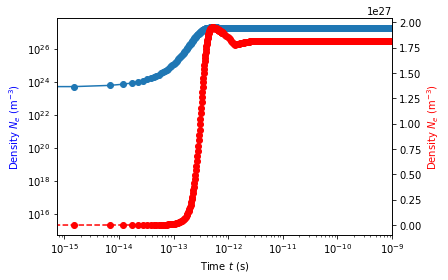

In [6]:
plt.figure()
ax1=plt.subplot(111)
ax1.loglog(data.Time_s+delay, data.Ne_mmin3, '-o')
ax1.set_xlabel(r"Time $t$ (s)")
ax1.set_ylabel(r"Density $N_e$ (m$^{-3}$)", color="blue")
ax12 = ax1.twinx()
ax12.semilogx(data.Time_s+delay, data.Ne_mmin3, 'r--o')
ax12.set_ylabel(r"Density $N_e$ (m$^{-3}$)", color="red")
plt.xlim([tlimmin,tlimmax])
plt.savefig("Time-Ne.eps")
plt.show()

## Te(t)

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:9: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  if __name__ == '__main__':


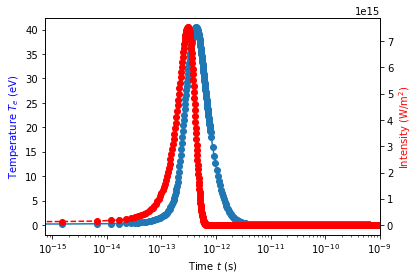

In [7]:
plt.figure()
ax1=plt.subplot(111)
ax1.semilogx(data.Time_s+delay, data.Te_K/11600., '-o')
plt.ylabel(r"Temperature $T_e$ (eV)", color="blue")
ax12 = ax1.twinx()
ax12.semilogx(data.Time_s+delay, data.Intensity_Wm2, 'r--o')
ax1.set_xlabel(r"Time $t$ (s)")
ax12.set_ylabel(r"Intensity (W/m$^{2}$)", color="red")
plt.xlim([tlimmin,tlimmax])
plt.savefig("Time-Te.eps")
plt.show()

## $T_i(t)$

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:9: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  if __name__ == '__main__':


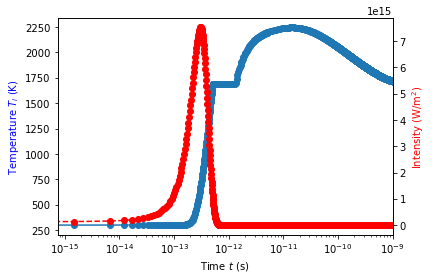

In [8]:
plt.figure()
ax1=plt.subplot(111)
ax1.semilogx(data.Time_s+delay, data.Ti_K, '-o')
plt.ylabel(r"Temperature $T_i$ (K)", color="blue")
ax12 = ax1.twinx()
ax12.semilogx(data.Time_s+delay, data.Intensity_Wm2, 'r--o')
ax1.set_xlabel(r"Time $t$ (s)")
ax12.set_ylabel(r"Intensity (W/m$^{2}$)", color="red")
plt.xlim([tlimmin,tlimmax])
plt.savefig("Time-Ti.eps")
plt.show()

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:10: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  # Remove the CWD from sys.path while we load stuff.


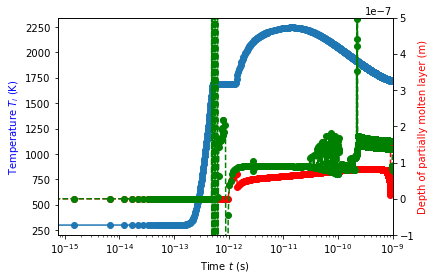

In [9]:
plt.figure()
ax1=plt.subplot(111)
ax1.plot(data.Time_s+delay, data.Ti_K, '-o')
plt.ylabel(r"Temperature $T_i$ (K)", color="blue")
ax12 = ax1.twinx()
ax12.semilogx(data.Time_s+delay, data.zMaxLiquid_m, 'r--o')
ax12.semilogx(data.Time_s+delay, data.zMaxLiquidMixture_m, 'g--o')
ax1.set_xlabel(r"Time $t$ (s)")
ax12.set_ylabel(r"Depth of partially molten layer (m)", color="red")
plt.xlim([tlimmin,tlimmax])
ax12.set_ylim([-100E-9,500e-9])
plt.savefig("Time-SolidLiquidDepth.eps")
plt.show()

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:9: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  if __name__ == '__main__':


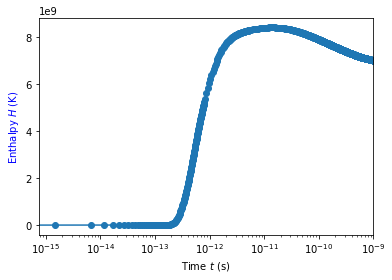

In [10]:
plt.figure()
ax1=plt.subplot(111)
ax1.semilogx(data.Time_s+delay, data.Henthalpy_J, '-o')
plt.ylabel(r"Enthalpy $H$ (K)", color="blue")
# ax12 = ax1.twinx()
# ax12.loglog(data.Time_s+delay, data.zMaxLiquidMixture_m, 'r--o')
ax1.set_xlabel(r"Time $t$ (s)")
# ax12.set_ylabel(r"Depth of partially molten layer (m)", color="red")
plt.xlim([tlimmin,tlimmax])
plt.savefig("Time-Enthalpy.eps")
plt.show()

## $\varepsilon(t)$

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/ipykernel_launcher.py:9: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  if __name__ == '__main__':


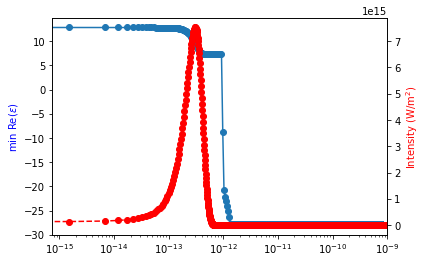

In [11]:
plt.figure()
ax1=plt.subplot(111)
ax1.semilogx(data.Time_s+delay, data.minReEps, '-o')
plt.ylabel(r"min Re$(\varepsilon)$", color="blue")
ax12 = ax1.twinx()
ax12.semilogx(data.Time_s+delay, data.Intensity_Wm2, 'r--o')
plt.xlabel(r"Time $t$ (s)")
plt.ylabel(r"Intensity (W/m$^{2}$)", color="red")
plt.xlim([tlimmin,tlimmax])
plt.savefig("Time-MinReEps.eps")
plt.show()

# Main output (t,z)

## Intensity(z;t)

In [12]:
data=pd.read_csv("Main35.dat", sep="\t", header=0, skip_blank_lines=True)
datafull=data
data.describe(include="all")
data=data.rename(columns={"#Wavelength_m": "Wavelength_m"})

In [13]:
data=data.convert_dtypes()
data.dtypes

Wavelength_m                      float64
Fluence_Jm2                         Int64
Time_s                            float64
X_m                               float64
Z_m                               float64
Te_K                              float64
TeOld_K                           float64
Ti_K                              float64
Ne_mmin3                          float64
 NeOld_mmin3                      float64
Nh_mmin3                          float64
NhOld_mmin3                       float64
IntensityX_Wm2                    float64
Intensity_Wm3                     float64
H_Jm3                             float64
Href_Wm3                          float64
Phase                               Int64
Angle_incidence_deg                 Int64
Angle_refracted_deg                 Int64
Surface_tension                     Int64
Htotal_Jm3                        float64
LiquidRatio_perc                  float64
DielectricReal                    float64
Pump_absorption_perc              

In [14]:
# from scipy.constants import e
data=data[data.X_m==0] #select 1D
# set(data.Egap2d_J/e)

In [15]:
data[data.Intensity_Wm3<0]

,Wavelength_m,Fluence_Jm2,Time_s,X_m,Z_m,Te_K,TeOld_K,Ti_K,Ne_mmin3,NeOld_mmin3,...,Htotal_Jm3,LiquidRatio_perc,DielectricReal,Pump_absorption_perc,Probe_absorption_perc,Egap2d_J,NonThermalLiquidRatio,KeldyshExcitationRate_wpi,KeldyshTable_IntensityBranched,NumberOfPhotons


In [16]:
print(np.min(data.Intensity_Wm3), np.max(data.Intensity_Wm3))
print(np.min(data.KeldyshTable_IntensityBranched), np.max(data.KeldyshTable_IntensityBranched))
print(np.max(data.KeldyshExcitationRate_wpi))
print(np.min(data.Time_s), np.max(data.Time_s))

0.0 7526430000000000.0
0 0
0
-1e-12 2.50001e-11


## I(t,z) and $N_e(t,z)$

/home/thibault.derrien/.conda/envs/octopus_slabs/lib/python3.6/site-packages/pandas/core/series.py:726: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


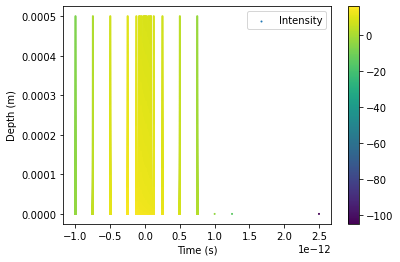

In [17]:
pointsize=1
# data.plot.scatter(x="Time_s", y="Z_m", c="KeldyshExcitationRate_wpi")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Egap2d_J/e), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=np.log10(data.Intensity_Wm3), s=pointsize, label="Intensity")
# plt.scatter(data.Time_s, data.Z_m, c=np.log10(data.Ne_mmin3), s=pointsize)
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.yscale("log")
# plt.xlim([-20e-15, -10e-15])
plt.colorbar()
plt.legend()
plt.savefig("Time-Depth-IntensityLog.png")
plt.show()



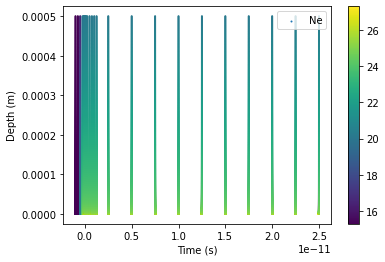

In [18]:
plt.figure()
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=np.log10(data.Ne_mmin3), s=pointsize, label="Ne")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.yscale("log")
# plt.xlim([-20e-15, -10e-15])
plt.colorbar()
plt.legend()
plt.savefig("Time-Depth-NeLog.png")
plt.show()

## $T_e(t,z)$

In [ ]:
plt.figure()
plt.title(r"$T_e$ (eV)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=(data.Te_K/11600), s=pointsize, label="Te")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
plt.ylim([0, 100E-9])
plt.colorbar()
plt.legend()
plt.savefig("Time-Depth-Te_eV.png")
plt.show()

KeyboardInterrupt: 

## $T_i(t,z)$

In [ ]:
plt.figure()
plt.title(r"$T_i$ (K)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=(data.Ti_K), s=pointsize, label="Ti")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
plt.ylim([0, 300e-9])
plt.colorbar()
plt.legend()
plt.savefig("Time-Depth-Ti_K.png")
plt.show()

## $w_{PI}(t,z)$

In [ ]:
plt.figure()
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
# plt.scatter(data.Time_s, data.Z_m, c=(data.DielectricReal), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=data.KeldyshExcitationRate_wpi, s=pointsize, label="Wpi")
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.xlim([-30e-15, 0e-15])
plt.legend()
plt.colorbar()
plt.savefig("Time-Depth-Wpi.png")
plt.show()

In [ ]:
plt.figure()
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
# plt.scatter(data.Time_s, data.Z_m, c=(data.DielectricReal), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=(data.NumberOfPhotons), s=pointsize, label="Number of photons")
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.xlim([-30e-15, 0e-15])
plt.legend()
plt.colorbar()
plt.savefig("Time-Depth-Nphotons.png")
plt.show()

In [ ]:
RelError=(data.Intensity_Wm3-data.KeldyshTable_IntensityBranched)/data.Intensity_Wm3
plt.figure()
plt.scatter(data.Time_s, data.Z_m, c=RelError, s=pointsize, label="Relative error")
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.xlim([-30e-15, 0e-15])
plt.legend()
plt.colorbar()
plt.savefig("Time-Depth-IntensityRelError.png")
plt.show()

## $H_m(t,z)$

In [ ]:
pointsize=1
plt.figure()
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=np.log10(data.H_Jm3), s=pointsize, label=r"H (J/m$^3$)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.yscale("log")
plt.ylim([0, 1E-6])
plt.colorbar()
plt.clim([8,10])

# plt.legend()
plt.savefig("Time-Depth-logHenthalpy.png")
plt.show()

In [ ]:
plt.figure()
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=np.log10(data.Href_Wm3), s=pointsize, label=r"H (J/m$^3$)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
# plt.yscale("log")
# plt.clim([-20e-15, -10e-15])
plt.clim([0,10])
plt.colorbar()
# plt.legend()
plt.savefig("Time-Depth-logHrefenthalpy.png")
plt.show()

In [ ]:
plt.figure()
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.Z_m, c=((data.H_Jm3 - data.Href_Wm3)/data.Href_Wm3), s=pointsize, label=r"H (J/m$^3$)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
plt.clim([0,100])
# plt.yscale("log")
# plt.xlim([-20e-15, -10e-15])
plt.colorbar()
# plt.legend()
plt.savefig("Time-Depth-HminusHrefRel.png")
plt.show()

# Technical aspects

In [ ]:
plt.figure()
plt.plot(data.Time_s, data.Intensity_Wm3, label="intensity")
plt.legend()

plt.figure()
plt.scatter(data.Z_m, data.Intensity_Wm3, label="intensity")
plt.legend()

In [ ]:
plt.figure()
plt.plot(data.Time_s, RelError, label="Error rel.")
plt.legend()

plt.figure()
plt.plot(data.Z_m, RelError, label="Error rel.")
plt.legend()

In [ ]:
plt.plot(data.Time_s, data.KeldyshExcitationRate_wpi, label="Wpi")
plt.legend()

In [ ]:
np.min(data.KeldyshExcitationRate_wpi)

In [ ]:
plt.plot(data.Time_s, data.Ne_mmin3, label="Ne")
plt.legend()

# 2D Results (t,x)

In [ ]:
data=pd.read_csv("Main0.dat", sep="\t", header=0, skip_blank_lines=True)
datafull=data
data.describe(include="all")
data=data.rename(columns={"#Wavelength_m": "Wavelength_m"})
# data=data.convert_dtypes()
data.dtypes

In [ ]:
pointsize=1
colormap=plt.cm.terrain
plt.figure()
ax1=plt.subplot(111)
plt.title(r"$T_i$ (K)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.X_m, c=data.TeOld_K, s=pointsize, cmap=colormap, label="Ti")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
# ax1.set_xscale('log')
plt.ylabel("Position at surface (m)")
plt.xlim([-250e-15, 250E-15])
plt.colorbar()
# plt.legend()
plt.savefig("Time-Surface-Ti_K.png")
plt.show()

In [ ]:
pointsize=1


## GOOD! plt.cm.terrain
## Good, but NaN = 300 K, not cool. plt.cm.hot_r
## Too much: plt.cm.flag 
## BOF: plt.cm.RdBu_r, plt.cm.twilight, plt.cm.hsv
## USELESS: plt.cm.RdBu_r


plt.figure()
ax1=plt.subplot(111)
plt.title(r"$T_i$ (K)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.X_m, c=data.TeOld_K, s=pointsize, cmap=colormap, label="Ti")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
# ax1.set_xscale('log')
plt.ylabel("Position at surface (m)")
plt.xlim([-0.25e-12, 5E-12])
plt.colorbar()
# plt.legend()
plt.savefig("Time-Surface-Ti_K-Longer.png")
plt.show()

In [ ]:
pointsize=1
plt.figure()
ax1=plt.subplot(111)
plt.title(r"$T_i$ (K)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.X_m, c=np.gradient(data.TeOld_K.values)/data.TeOld_K.values, s=pointsize, cmap=colormap, label="Ti")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
# ax1.set_xscale('log')
plt.ylabel("Position at surface (m)")
plt.xlim([-2e-12, 2E-12])
plt.colorbar()
# plt.legend()
plt.savefig("Time-Surface-Ti_K-Gradient.png")
plt.show()

In [ ]:
plt.figure()
plt.xlabel("Surface position (m)")
plt.ylabel("Lattice temperature (K)")
plt.plot(data.X_m, data.TeOld_K.values, ".")
plt.show()

In [ ]:
pointsize=1
colormap=plt.cm.terrain
plt.figure()
ax1=plt.subplot(111)
plt.title(r"$N_{exc}$ (m$^{-3}$)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.X_m, c=data.Ne_mmin3, s=pointsize, cmap=colormap, label="Ti")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
# ax1.set_xscale('log')
plt.ylabel("Position at surface (m)")
plt.xlim([-250e-15, 250E-15])
plt.colorbar()
# plt.legend()
plt.savefig("Time-Surface-Nexc_K.png")
plt.show()

In [ ]:
pointsize=1
colormap=plt.cm.RdBu_r
plt.figure()
ax1=plt.subplot(111)
plt.title(r"$\varepsilon$")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.X_m, c=data.Surface_tension, s=pointsize, cmap=colormap, label="Ti") #error in column indexing
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
# ax1.set_xscale('log')
plt.ylabel("Position at surface (m)")
plt.xlim([-250e-15, 250E-15])
plt.colorbar()
# plt.legend()
plt.savefig("Time-Surface-ReEps.png")
plt.show()

In [ ]:
pointsize=1
colormap=plt.cm.RdBu_r
plt.figure()
ax1=plt.subplot(111)
plt.title(r"$\varepsilon$")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data.Time_s, data.X_m, c=data.Surface_tension, s=pointsize, cmap=colormap, label="Ti") #error in column indexing
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
# ax1.set_xscale('log')
plt.ylabel("Position at surface (m)")
plt.xlim([-250e-15, 5000E-15])
plt.colorbar()
# plt.legend()
plt.savefig("Time-Surface-ReEps_long.png")
plt.show()

In [ ]:
%pwd

# Molten depth vs max temperature

Here we reconstruct the results usually obtained via BuildZofFluence.sh.

In [ ]:
data_select_Href=data[(data.H_Jm3-data.Href_Wm3)/data.Href_Wm3>0.99] #criterion for partial melting

In [ ]:
data_select_Href

In [ ]:
data_select_T=data[data.Ti_K>1687]

In [ ]:
data_select_T

In [ ]:
pointsize=1
plt.figure()
plt.title(r"$T_i$ (K)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data_select_Href.Time_s, data_select_Href.Z_m, c=(data_select_Href.Ti_K), s=pointsize, label="Ti")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
plt.ylim([0, 40e-9])
plt.colorbar()
plt.legend()
plt.savefig("Time-Depth-Ti_K.png")
plt.show()

In [ ]:
print(min(data_select_Href.LiquidRatio_perc), max(data_select_Href.LiquidRatio_perc))

It's pretty strange that molten fraction gets down to 75%, while (H-Href)/Href indeed gives the result extracted by the script buildZofFluence.sh (!!).

In [ ]:
pointsize=1
plt.figure()
plt.title(r"$T_i$ (K)")
# plt.scatter(data.Time_s, data.Z_m, c=(data.Intensity_Wm3), s=pointsize)
plt.scatter(data_select_Href.Time_s, data_select_Href.Z_m, c=(data_select_Href.LiquidRatio_perc), s=pointsize, label="Ti")
# plt.scatter(data.Time_s, data.Z_m, c=(data.KeldyshExcitationRate_wpi), s=pointsize)
plt.xlabel("Time (s)")
plt.ylabel("Depth (m)")
plt.ylim([0, 40e-9])
plt.colorbar()
plt.legend()
plt.savefig("Time-Depth-LiquidRatio.png")
plt.show()